# Module 1 — Understanding the problem and the data
**African Credit Scoring Challenge · 3MTT Mentorship**

Goal of this notebook: by the end you should be able to explain every column, the grain of the data, how train differs from test (especially Ghana), and how the external economic data connects to the loans.

How to use it:
- Run each cell, then read the **Mentor note** under it.
- Cells marked `# TODO` are yours. Write the code, then write 1–3 sentences on what you found.
- Do not change the data files. Write any outputs to an `outputs/` folder.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
DATA = Path('.')          # notebook sits in the project folder next to the CSVs
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)

train = pd.read_csv(DATA / 'Train.csv', parse_dates=['disbursement_date', 'due_date'])
test  = pd.read_csv(DATA / 'Test.csv',  parse_dates=['disbursement_date', 'due_date'])
econ  = pd.read_csv(DATA / 'economic_indicators.csv')
print('train', train.shape, '| test', test.shape, '| econ', econ.shape)

train (68654, 16) | test (18594, 15) | econ (27, 25)


## 1. First look: types, missing values, the target

In [2]:
display(train.head())

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0
3,ID_266004285009267278,266004,Kenya,285009,267278,Type_1,8958.0,9233.0,2022-10-20,2022-10-27,7,Repeat Loan,2687.40,0.300000,2770.0,0
4,ID_253803305312267278,253803,Kenya,305312,267278,Type_1,4564.0,4728.0,2022-11-28,2022-12-05,7,Repeat Loan,1369.20,0.300000,1418.0,0


In [3]:
print(train.dtypes)

ID                                        str
customer_id                             int64
country_id                                str
tbl_loan_id                             int64
lender_id                               int64
loan_type                                 str
Total_Amount                          float64
Total_Amount_to_Repay                 float64
disbursement_date              datetime64[us]
due_date                       datetime64[us]
duration                                int64
New_versus_Repeat                         str
Amount_Funded_By_Lender               float64
Lender_portion_Funded                 float64
Lender_portion_to_be_repaid           float64
target                                  int64
dtype: object


In [4]:


print('Missing values  train:', train.isna().sum().sum(), ' test:', test.isna().sum().sum())
print(train['target'].value_counts().rename('count').to_frame().assign(share=lambda d: d['count'] / d['count'].sum()))

Missing values  train: 0  test: 0
        count     share
target                 
0       67396  0.981676
1        1258  0.018324


**Mentor note.** Only ~1.8% of rows are defaults. That is a *severely imbalanced* problem. A model that predicts 0 for everyone gets 98% accuracy and is worthless, which is why the competition uses F1.

## 2. The grain: customer → loan → lender share

In [5]:
rows_per_customer = train.groupby('customer_id').size()
lenders_per_loan  = train.groupby('tbl_loan_id')['lender_id'].nunique()
print('customers:', train.customer_id.nunique(), '| distinct loans:', train.tbl_loan_id.nunique(), '| rows:', len(train))
print('rows per customer:'); print(rows_per_customer.describe().round(1))
print('loans funded by >1 lender:', (lenders_per_loan > 1).sum())
print('loans whose target differs across lender rows:', (train.groupby('tbl_loan_id').target.nunique() > 1).sum())
print('customers with both repaid and defaulted loans:', (train.groupby('customer_id').target.nunique() > 1).sum())

customers: 6540 | distinct loans: 66520 | rows: 68654
rows per customer:
count    6540.0
mean       10.5
std        13.0
min         1.0
25%         2.0
50%         6.0
75%        14.0
max       208.0
dtype: float64
loans funded by >1 lender: 2134
loans whose target differs across lender rows: 2
customers with both repaid and defaulted loans: 634


In [6]:
# Pick one multi-lender loan and look at its rows side by side
example_loan = lenders_per_loan[lenders_per_loan > 1].index[0]
display(train[train.tbl_loan_id == example_loan])

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
32345,ID_248648126311245684,248648,Kenya,126311,245684,Type_5,40700.0,42835.0,2022-03-14,2022-03-28,14,Repeat Loan,10000.0,0.245700,10525.0,0
49684,ID_248648126311251804,248648,Kenya,126311,251804,Type_5,40700.0,42835.0,2022-03-14,2022-03-28,14,Repeat Loan,4980.0,0.122359,5241.0,0


**Mentor note.** One row = one lender's share of one loan. `Amount_Funded_By_Lender`, `Lender_portion_Funded` and `Lender_portion_to_be_repaid` describe *that lender's share*; `Total_Amount` and `Total_Amount_to_Repay` describe the whole loan.

## 3. Train vs test overlap

In [7]:
print('test countries:'); print(test.country_id.value_counts())
print('share of test rows whose customer is in train:', round(test.customer_id.isin(train.customer_id).mean(), 3))
for c in ['Kenya', 'Ghana']:
    t = test[test.country_id == c]
    print(f'  {c}: {t.customer_id.isin(train.customer_id).mean():.3f}')
print('share of test loan ids in train:', round(test.tbl_loan_id.isin(train.tbl_loan_id).mean(), 3))
print('lenders only in test:', sorted(set(test.lender_id) - set(train.lender_id)))
print('loan types only in test:', sorted(set(test.loan_type) - set(train.loan_type)))

test countries:
country_id
Kenya    15069
Ghana     3525
Name: count, dtype: int64
share of test rows whose customer is in train: 0.798
  Kenya: 0.984
  Ghana: 0.000
share of test loan ids in train: 0.049
lenders only in test: [296540, 296542, 297182, 297183]
loan types only in test: ['Type_3', 'Type_8']


**Mentor note.** Kenya test customers are mostly known; Ghana customers, most Ghana lenders and Ghana's main product (Type_3) are completely new. Your validation design in Module 2 must reflect both situations.

## 4. Default rate by segment

In [8]:
def rate_table(df, col, min_rows=1):
    t = df.groupby(col)['target'].agg(rows='size', defaults='sum', default_rate='mean')
    return t[t.rows >= min_rows].sort_values('rows', ascending=False)

for col in ['New_versus_Repeat', 'lender_id', 'loan_type', 'duration']:
    print(f'\n=== {col}')
    display(rate_table(train, col, min_rows=20).head(12).style.format({'default_rate': '{:.1%}'}))


=== New_versus_Repeat


,rows,defaults,default_rate
New_versus_Repeat,,,
Repeat Loan,68087,1139,1.7%
New Loan,567,119,21.0%



=== lender_id


,rows,defaults,default_rate
lender_id,,,
267278,64653,784,1.2%
251804,3542,316,8.9%
267277,271,80,29.5%
245684,188,78,41.5%



=== loan_type


,rows,defaults,default_rate
loan_type,,,
Type_1,61723,520,0.8%
Type_7,2790,235,8.4%
Type_5,1521,122,8.0%
Type_4,1235,152,12.3%
Type_10,466,12,2.6%
Type_6,357,38,10.6%
Type_9,205,36,17.6%
Type_14,99,71,71.7%
Type_2,74,45,60.8%



=== duration


,rows,defaults,default_rate
duration,,,
7,64973,791,1.2%
14,1567,129,8.2%
30,958,150,15.7%
90,249,59,23.7%
60,201,36,17.9%
45,118,7,5.9%
31,77,4,5.2%
29,61,0,0.0%
25,34,0,0.0%


In [9]:
# Markup = price of the loan relative to principal
train['markup'] = train['Total_Amount_to_Repay'] / train['Total_Amount'].clip(lower=1) - 1
train['markup_quintile'] = pd.qcut(train['markup'].rank(method='first'), 5, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4', 'Q5 highest'])
display(rate_table(train, 'markup_quintile').style.format({'default_rate': '{:.1%}'}))

,rows,defaults,default_rate
markup_quintile,,,
Q1 lowest,13731,1,0.0%
Q2,13731,1,0.0%
Q4,13731,5,0.0%
Q5 highest,13731,1235,9.0%
Q3,13730,16,0.1%


**Mentor note.** Riskier loans are priced higher, so the markup quintile separates defaulters sharply. Ask yourself whether the price is known at the time of the lending decision. (It is, so it is a legitimate feature.)

,rows,defaults,default_rate
duration_bucket,,,
0-7,65041,791,1.22%
8-14,1572,129,8.21%
15-30,1147,152,13.25%
31-90,742,118,15.90%
91-180,105,38,36.19%
181+,47,30,63.83%


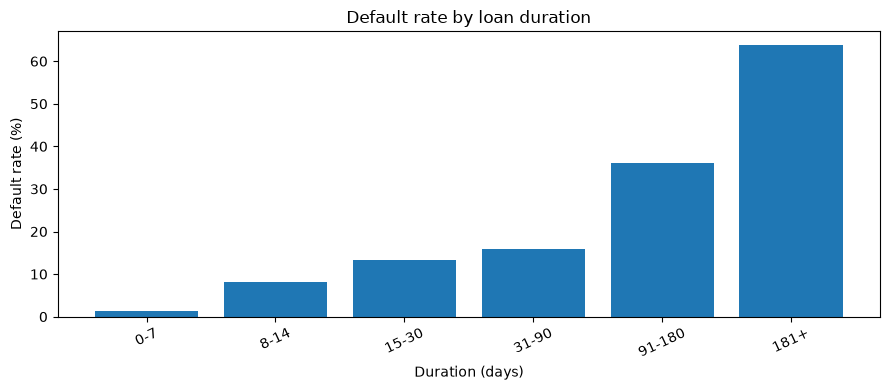

In [10]:
# Default rate by duration bucket
duration_bins = [0, 7, 14, 30, 90, 180, np.inf]
duration_labels = ['0-7', '8-14', '15-30', '31-90', '91-180', '181+']
train['duration_bucket'] = pd.cut(
    train['duration'],
    bins=duration_bins,
    labels=duration_labels,
    include_lowest=True,
    right=True
)

duration_rates = rate_table(train, 'duration_bucket').reindex(duration_labels)
display(duration_rates.style.format({'default_rate': '{:.2%}'}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(duration_rates.index.astype(str), duration_rates['default_rate'] * 100)
ax.set(title='Default rate by loan duration', xlabel='Duration (days)', ylabel='Default rate (%)')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

,rows,defaults,default_rate
markup_decile,,,
D1,6866,0,0.00%
D2,6865,1,0.01%
D3,6865,0,0.00%
D4,6866,1,0.01%
D5,6865,1,0.01%
D6,6865,15,0.22%
D7,6866,4,0.06%
D8,6865,1,0.01%
D9,6865,17,0.25%


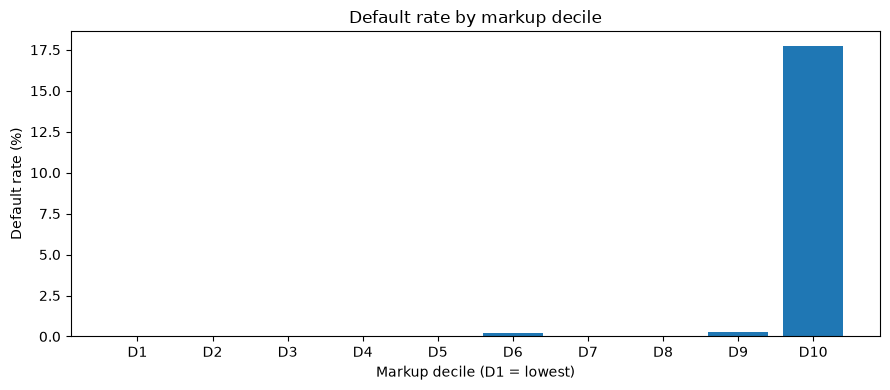

The maximum default rate across D1-D9 is 0.25%, while D10 defaults at 17.74%. The sharp concentration of defaults in the top markup decile suggests that a high-markup indicator or threshold may carry substantial predictive signal. Validate any cut-off on a leakage-safe validation set before using it in a model.


In [11]:
# Divide loans into ten approximately equal-sized markup groups.
# Rank first avoids qcut failures when multiple loans have identical markup.
train['markup_decile'] = pd.qcut(
    train['markup'].rank(method='first'),
    q=10,
    labels=[f'D{i}' for i in range(1, 11)]
)
decile_rates = rate_table(train, 'markup_decile').reindex([f'D{i}' for i in range(1, 11)])
display(decile_rates.style.format({'default_rate': '{:.2%}'}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(decile_rates.index.astype(str), decile_rates['default_rate'] * 100)
ax.set(title='Default rate by markup decile', xlabel='Markup decile (D1 = lowest)', ylabel='Default rate (%)')
plt.tight_layout()
plt.show()

# Interpretation from the observed decile rates:
# The print statement below reports the observed D1-D9 maximum and D10 default rate directly.
# This is a cliff at the highest markup decile, not a smooth, steady increase.
print(
    f"The maximum default rate across D1-D9 is "
    f"{decile_rates.loc['D1':'D9', 'default_rate'].max():.2%}, while D10 defaults at "
    f"{decile_rates.loc['D10', 'default_rate']:.2%}. "
    "The sharp concentration of defaults in the top markup decile suggests "
    "that a high-markup indicator or threshold may carry substantial predictive signal. "
    "Validate any cut-off on a leakage-safe validation set before using it in a model."
)

## 5. Vintage: default rate over time

,loans,default_rate
quarter,,
2021Q4,39,53.8%
2022Q1,585,18.3%
2022Q2,479,14.0%
2022Q3,40554,1.0%
2022Q4,22787,1.1%
2023Q1,347,11.2%
2023Q2,182,14.8%
2023Q3,372,13.4%
2023Q4,339,8.0%


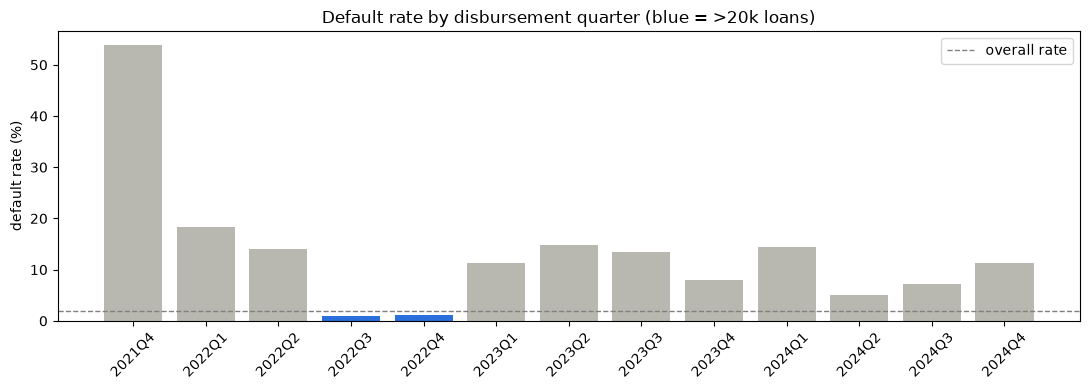

In [12]:
vintage = (train.assign(quarter=train.disbursement_date.dt.to_period('Q').astype(str))
                .groupby('quarter')['target'].agg(loans='size', default_rate='mean'))
display(vintage.style.format({'default_rate': '{:.1%}'}))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(vintage.index, vintage.default_rate * 100, color=['#2a6fdb' if n > 20000 else '#b8b8b0' for n in vintage.loans])
ax.axhline(train.target.mean() * 100, ls='--', c='grey', lw=1, label='overall rate')
ax.set_ylabel('default rate (%)'); ax.set_title('Default rate by disbursement quarter (blue = >20k loans)')
ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**Mentor note.** 92% of loans were disbursed in 2022 Q3–Q4 and defaulted at ~1%; most other quarters sit at 8–18%. Write down two business explanations (e.g., a product launch with tight limits, a change in which lender or product dominated) and how you would test each with this data.

,loans,default_rate,share_type_1,share_lender_267278
quarter,,,,
2021Q4,39,53.85%,0.00%,0.00%
2022Q1,585,18.29%,0.00%,0.00%
2022Q2,479,13.99%,0.00%,24.01%
2022Q3,40554,1.00%,98.46%,99.21%
2022Q4,22787,1.12%,95.65%,97.62%
2023Q1,347,11.24%,0.00%,48.99%
2023Q2,182,14.84%,0.00%,45.60%
2023Q3,372,13.44%,0.00%,60.48%
2023Q4,339,7.96%,0.00%,49.85%


,quarter,segment,rows,default_rate
0,2021Q4,All other rows,39,53.85%
1,2022Q1,All other rows,585,18.29%
2,2022Q2,All other rows,479,13.99%
3,2022Q3,All other rows,626,7.83%
4,2022Q3,Type_1 / lender 267278,39928,0.90%
5,2022Q4,All other rows,992,9.38%
6,2022Q4,Type_1 / lender 267278,21795,0.74%
7,2023Q1,All other rows,347,11.24%
8,2023Q2,All other rows,182,14.84%
9,2023Q3,All other rows,372,13.44%


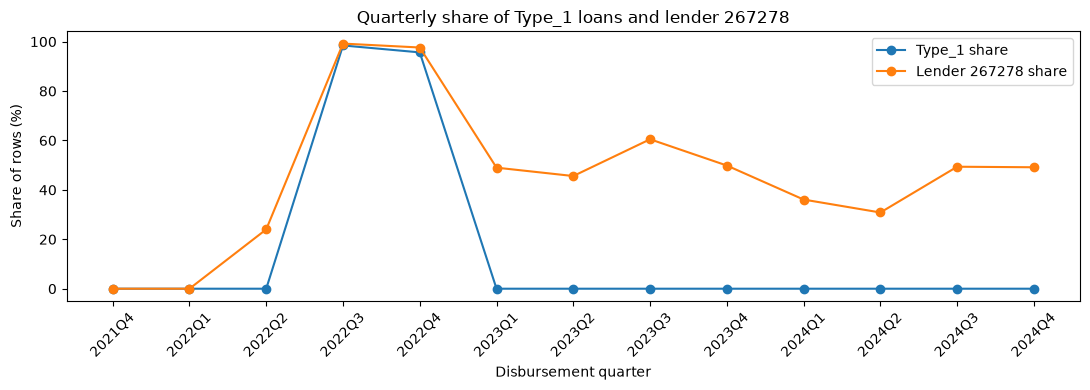

Type_1 makes up 96%-98% of rows in 2022Q3 and 2022Q4 and 0% in every other quarter. In those quarters, Type_1 / lender 267278 loans default at 0.7%-0.9%, while all other loans default at 7.8%-9.4%. In the remaining quarters (those with at least 100 loans), other loans default at 5.0%-18.3%. The vintage swing is mostly product/lender mix. This is an association, not proof of causation; customer mix, underwriting, loan size, duration and selection effects may also contribute.


In [13]:
# Compare quarter-by-quarter loan mix with the vintage default-rate pattern.
quarter_mix = (
    train.assign(quarter=train['disbursement_date'].dt.to_period('Q').astype(str))
         .groupby('quarter')
         .agg(
             loans=('target', 'size'),
             default_rate=('target', 'mean'),
             share_type_1=('loan_type', lambda s: s.eq('Type_1').mean()),
             share_lender_267278=('lender_id', lambda s: s.eq(267278).mean())
         )
         .sort_index()
)
display(quarter_mix.style.format({
    'default_rate': '{:.2%}',
    'share_type_1': '{:.2%}',
    'share_lender_267278': '{:.2%}'
}))

# Compare the specific Type_1 + lender 267278 segment with every other row.
quarter_segment = train.assign(
    quarter=train['disbursement_date'].dt.to_period('Q').astype(str),
    segment=np.where(
        train['loan_type'].eq('Type_1') & train['lender_id'].eq(267278),
        'Type_1 / lender 267278',
        'All other rows'
    )
).groupby(['quarter', 'segment'])['target'].agg(
    rows='size', default_rate='mean'
).reset_index()
display(quarter_segment.style.format({'default_rate': '{:.2%}'}))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(quarter_mix.index, quarter_mix['share_type_1'] * 100, marker='o', label='Type_1 share')
ax.plot(quarter_mix.index, quarter_mix['share_lender_267278'] * 100, marker='o', label='Lender 267278 share')
ax.set(title='Quarterly share of Type_1 loans and lender 267278', ylabel='Share of rows (%)', xlabel='Disbursement quarter')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

seg = quarter_segment.set_index(['segment', 'quarter'])
core = seg.loc['Type_1 / lender 267278']
other = seg.loc['All other rows']
peak = core.index.tolist()
other_peak = other.loc[peak, 'default_rate']
other_rest = other.drop(index=peak).query('rows >= 100')['default_rate']
t1 = quarter_mix.loc[peak, 'share_type_1']
print(
    f"Type_1 makes up {t1.min():.0%}-{t1.max():.0%} of rows in {' and '.join(peak)} "
    f"and {quarter_mix.drop(index=peak)['share_type_1'].max():.0%} in every other quarter. "
    f"In those quarters, Type_1 / lender 267278 loans default at {core['default_rate'].min():.1%}-{core['default_rate'].max():.1%}, "
    f"while all other loans default at {other_peak.min():.1%}-{other_peak.max():.1%}. "
    f"In the remaining quarters (those with at least 100 loans), other loans default at "
    f"{other_rest.min():.1%}-{other_rest.max():.1%}. The vintage swing is mostly product/lender mix. "
    "This is an association, not proof of causation; customer mix, underwriting, loan size, duration "
    "and selection effects may also contribute."
)

## 6. Data quality checks

In [14]:
checks = {
    'due_date - disbursement_date != duration': ((train.due_date - train.disbursement_date).dt.days != train.duration).sum(),
    'Total_Amount_to_Repay < Total_Amount': (train.Total_Amount_to_Repay < train.Total_Amount).sum(),
    'Total_Amount_to_Repay == 0': (train.Total_Amount_to_Repay == 0).sum(),
    'Lender_portion_Funded > 1': (train.Lender_portion_Funded > 1).sum(),
    'Amount_Funded_By_Lender == 0': (train.Amount_Funded_By_Lender == 0).sum(),
    'duplicate ID': train.ID.duplicated().sum(),
}
pd.Series(checks, name='rows')

due_date - disbursement_date != duration       0
Total_Amount_to_Repay < Total_Amount          72
Total_Amount_to_Repay == 0                     3
Lender_portion_Funded > 1                      1
Amount_Funded_By_Lender == 0                8520
duplicate ID                                   0
Name: rows, dtype: int64

In [15]:
# Inspect examples for every non-zero data-quality check.
# The counts below are defined in the preceding cell; this maps each check to its row-level condition.
check_conditions = {
    'due_date - disbursement_date != duration':
        (train['due_date'] - train['disbursement_date']).dt.days.ne(train['duration']),
    'Total_Amount_to_Repay < Total_Amount':
        train['Total_Amount_to_Repay'].lt(train['Total_Amount']),
    'Total_Amount_to_Repay == 0':
        train['Total_Amount_to_Repay'].eq(0),
    'Lender_portion_Funded > 1':
        train['Lender_portion_Funded'].gt(1),
    'Amount_Funded_By_Lender == 0':
        train['Amount_Funded_By_Lender'].eq(0),
    'duplicate ID':
        train['ID'].duplicated(keep=False),
}

for check_name, mask in check_conditions.items():
    n = int(mask.sum())
    print(f'\n{check_name}: {n} affected rows')
    if n:
        cols = [c for c in [
            'ID', 'customer_id', 'tbl_loan_id', 'lender_id', 'country_id',
            'disbursement_date', 'due_date', 'duration', 'loan_type',
            'Total_Amount', 'Total_Amount_to_Repay',
            'Amount_Funded_By_Lender', 'Lender_portion_Funded',
            'Lender_portion_to_be_repaid', 'target'
        ] if c in train.columns]
        display(train.loc[mask, cols].head(20))

# Quantify the most important patterns before deciding how to treat the records.
zero_funded = train['Amount_Funded_By_Lender'].eq(0)
print(f"Zero-funded rows: {zero_funded.sum():,} ({zero_funded.mean():.1%} of training rows)")
print("Zero-funded rows by lender:")
display(train.loc[zero_funded].groupby('lender_id').agg(
    rows=('target', 'size'),
    default_rate=('target', 'mean'),
    type_1_share=('loan_type', lambda s: s.eq('Type_1').mean()),
    other_loan_types=('loan_type', lambda s: s.ne('Type_1').sum())
).sort_values('rows', ascending=False))

print("Zero-funded rows by target:")
display(train.loc[zero_funded].groupby('target').size().rename('rows').to_frame())

below_principal = train['Total_Amount_to_Repay'].lt(train['Total_Amount'])
print(f"Rows where repayment is below principal: {below_principal.sum()} "
      f"(all target=0: {train.loc[below_principal, 'target'].eq(0).all()})")

overfunded = train['Lender_portion_Funded'].gt(1)
display(train.loc[overfunded, [
    'ID', 'tbl_loan_id', 'lender_id', 'Total_Amount',
    'Amount_Funded_By_Lender', 'Lender_portion_Funded', 'target'
]])

print(
    "Triage: prioritize the 8,520 zero-funded rows. All are lender 267278 and all "
    "have target=0; all but two are Type_1. This may reflect a genuine unfunded-share "
    "record or a target/label recording process that systematically marks these rows "
    "as non-default. Do not use this field or drop these rows until the client confirms "
    "how funding and the target are recorded. The 72 repayment-below-principal rows "
    "also all have target=0; confirm whether discounts, write-offs or corrections explain "
    "them. The single portion-above-1 row is inconsistent with a fractional share: "
    "2,627.10 funded against total principal of 2,249. Confirm and correct at source. "
    "There are zero date-duration mismatches and zero duplicate IDs, so no remediation "
    "is indicated for those checks."
)



due_date - disbursement_date != duration: 0 affected rows

Total_Amount_to_Repay < Total_Amount: 72 affected rows


,ID,customer_id,tbl_loan_id,lender_id,country_id,disbursement_date,due_date,duration,loan_type,Total_Amount,Total_Amount_to_Repay,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
70,ID_260863236259267278,260863,236259,267278,Kenya,2022-08-13,2022-08-20,7,Type_1,949.00,932.00,284.7,0.300000,287.0,0
726,ID_259843306527251804,259843,306527,251804,Kenya,2023-02-01,2023-02-28,27,Type_10,246150.00,207624.25,21683.0,0.088089,22008.0,0
911,ID_271535263157267278,271535,263157,267278,Kenya,2022-09-19,2022-09-26,7,Type_5,300.00,299.50,48.0,0.160000,66.0,0
1763,ID_256566235585267278,256566,235585,267278,Kenya,2022-08-12,2022-08-19,7,Type_1,870.00,857.00,261.0,0.300000,266.0,0
3843,ID_267330230417267278,267330,230417,267278,Kenya,2022-08-02,2022-08-09,7,Type_1,7497.00,6327.00,2249.1,0.300000,2346.0,0
5651,ID_241346236789267278,241346,236789,267278,Kenya,2022-08-13,2022-08-20,7,Type_1,1180.00,1024.00,354.0,0.300000,357.0,0
8692,ID_245234236074267278,245234,236074,267278,Kenya,2022-08-13,2022-08-20,7,Type_1,1300.00,1291.00,390.0,0.300000,396.0,0
9127,ID_251142230435267278,251142,230435,267278,Kenya,2022-08-02,2022-08-09,7,Type_1,6249.00,5051.00,1874.7,0.300000,1898.0,0
9175,ID_270581256924267278,270581,256924,267278,Kenya,2022-09-10,2022-09-17,7,Type_1,1000.00,793.00,300.0,0.300000,308.0,0
9652,ID_264732236574267278,264732,236574,267278,Kenya,2022-08-13,2022-08-20,7,Type_1,216.00,169.00,0.0,0.000000,0.0,0



Total_Amount_to_Repay == 0: 3 affected rows


,ID,customer_id,tbl_loan_id,lender_id,country_id,disbursement_date,due_date,duration,loan_type,Total_Amount,Total_Amount_to_Repay,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
14942,ID_259525295227267278,259525,295227,267278,Kenya,2022-11-07,2022-11-14,7,Type_1,2259.0,0.0,677.7,0.300,678.0,0
46044,ID_248700232519251804,248700,232519,251804,Kenya,2022-08-05,2022-09-04,30,Type_13,500.0,0.0,133.0,0.266,142.0,0
58838,ID_262903231904267278,262903,231904,267278,Kenya,2022-08-04,2022-08-11,7,Type_1,290.0,0.0,87.0,0.300,92.0,0



Lender_portion_Funded > 1: 1 affected rows


,ID,customer_id,tbl_loan_id,lender_id,country_id,disbursement_date,due_date,duration,loan_type,Total_Amount,Total_Amount_to_Repay,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
30684,ID_255356215046267278,255356,215046,267278,Kenya,2022-07-14,2022-07-21,7,Type_1,2249.0,2249.0,2627.1,1.168119,2627.0,0


... (5 outputs left out)

,rows
target,
0,8520


Rows where repayment is below principal: 72 (all target=0: True)


,ID,tbl_loan_id,lender_id,Total_Amount,Amount_Funded_By_Lender,Lender_portion_Funded,target
30684,ID_255356215046267278,215046,267278,2249.0,2627.1,1.168119,0


Triage: prioritize the 8,520 zero-funded rows. All are lender 267278 and all have target=0; all but two are Type_1. This may reflect a genuine unfunded-share record or a target/label recording process that systematically marks these rows as non-default. Do not use this field or drop these rows until the client confirms how funding and the target are recorded. The 72 repayment-below-principal rows also all have target=0; confirm whether discounts, write-offs or corrections explain them. The single portion-above-1 row is inconsistent with a fractional share: 2,627.10 funded against total principal of 2,249. Confirm and correct at source. There are zero date-duration mismatches and zero duplicate IDs, so no remediation is indicated for those checks.


## 7. Currency: putting Kenya and Ghana on one scale

In [16]:
econ_long = (econ.melt(id_vars=['Country', 'Indicator'], var_name='year', value_name='value')
                 .assign(year=lambda d: d.year.str.replace('YR', '').astype(int)))
short = {
    'Inflation, consumer prices (annual %)': 'inflation',
    'Official exchange rate (LCU per US$, period average)': 'fx_lcu_per_usd',
    'Real interest rate (%)': 'real_rate',
    'Average precipitation in depth (mm per year)': 'precipitation',
    'Deposit interest rate (%)': 'deposit_rate',
    'Lending interest rate (%)': 'lending_rate',
    'Interest rate spread (lending rate minus deposit rate, %)': 'rate_spread',
    'Fossil fuel energy consumption (% of total)': 'fossil_fuel',
    'Unemployment rate': 'unemployment',
}
econ_wide = (econ_long.assign(indicator=lambda d: d.Indicator.map(short))
                      .pivot_table(index=['Country', 'year'], columns='indicator', values='value')
                      .reset_index().rename(columns={'Country': 'country_id'}))
display(econ_wide[econ_wide.country_id.isin(['Kenya', 'Ghana']) & (econ_wide.year >= 2020)].round(2))

indicator,country_id,year,deposit_rate,fossil_fuel,fx_lcu_per_usd,inflation,lending_rate,precipitation,rate_spread,real_rate,unemployment
42,Ghana,2020,11.50,NaN,5.60,9.89,NaN,1187.0,NaN,NaN,3.28
43,Ghana,2021,11.50,NaN,5.81,9.97,NaN,1187.0,NaN,NaN,3.34
44,Ghana,2022,12.05,NaN,8.27,31.26,NaN,NaN,NaN,NaN,3.08
45,Ghana,2023,11.42,NaN,11.02,38.11,NaN,NaN,NaN,NaN,3.08
65,Kenya,2020,6.97,NaN,106.45,5.41,12.00,630.0,5.03,6.71,5.62
66,Kenya,2021,6.69,NaN,109.64,6.11,12.08,630.0,5.39,7.43,5.69
67,Kenya,2022,7.15,NaN,117.87,7.66,12.34,NaN,5.19,5.97,5.80
68,Kenya,2023,9.17,NaN,139.85,7.67,13.59,NaN,4.42,6.55,5.68


**Mentor note.** The file stops at 2023, while loans run to late 2024. A safe, defensible rule: join each loan to the **previous** year's figures (`macro_year = disbursement year − 1`). A real lender only knows last year's published statistics when deciding.

In [17]:
def add_macro(df):
    out = df.copy()
    out['macro_year'] = (out.disbursement_date.dt.year - 1).clip(upper=econ_wide.year.max())
    return out.merge(econ_wide, left_on=['country_id', 'macro_year'], right_on=['country_id', 'year'], how='left').drop(columns='year')

test_m = add_macro(test)
test_m['amount_usd'] = test_m.Total_Amount / test_m.fx_lcu_per_usd
print('rows missing an exchange rate:', test_m.fx_lcu_per_usd.isna().sum())
display(test_m.groupby('country_id')[['Total_Amount', 'amount_usd']].describe().T.round(1))

rows missing an exchange rate: 0


country_id             Ghana       Kenya
Total_Amount count    3525.0     15069.0
             mean    15536.9     14214.3
             std     36974.1    173377.8
             min       354.7         5.0
             25%      1580.8      2287.0
             50%      3001.9      5149.0
             75%      5923.7     11111.0
             max    278110.4  20000000.0
amount_usd   count    3525.0     15069.0
             mean     2583.5       126.9
             std      6234.6      1570.0
             min        61.1         0.0
             25%       264.2        20.8
             50%       494.4        46.2
             75%       976.6       100.7
             max     49700.7    182418.9

Training rows missing an exchange rate: 0


Total_Amount                                                                amount_usd                                                      
                  count      mean        std  min     25%     50%      75%         max      count   mean      std   min    25%    50%    75%        max
country_id                                                                                                                                             
Kenya           68654.0  14836.83  141649.87  2.0  2295.0  5249.0  11450.0  23000000.0    68654.0  132.4  1272.42  0.01  20.85  47.41  103.4  209781.77

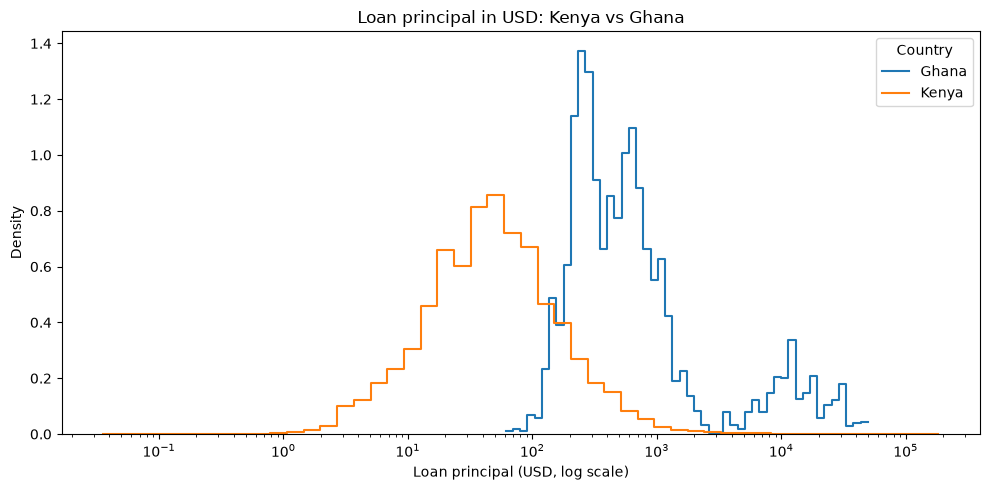

Median principal: $494 in Ghana vs $46 in Kenya (10.7x). The middle-50% ranges do not overlap: Ghana's 25th percentile ($264) is above Kenya's 75th percentile ($101).


,country_id,indicator,all_missing,constant_non_missing,non_missing_years,distinct_non_missing_values
0,Kenya,deposit_rate,False,False,4,4
1,Kenya,fossil_fuel,True,False,0,0
2,Kenya,fx_lcu_per_usd,False,False,4,4
3,Kenya,inflation,False,False,4,4
4,Kenya,lending_rate,False,False,4,4
5,Kenya,precipitation,False,True,2,1
6,Kenya,rate_spread,False,False,4,4
7,Kenya,real_rate,False,False,4,4
8,Kenya,unemployment,False,False,4,4
9,Ghana,deposit_rate,False,False,4,3


Columns empty in both countries: ['fossil_fuel']
Columns constant within each country (review these before dropping):


,country_id,indicator,all_missing,constant_non_missing,non_missing_years,distinct_non_missing_values
14,Ghana,precipitation,False,True,2,1
5,Kenya,precipitation,False,True,2,1


Keep (varying and present for both countries): ['deposit_rate', 'fx_lcu_per_usd', 'inflation', 'unemployment']
Drop: ['fossil_fuel', 'lending_rate', 'precipitation', 'rate_spread', 'real_rate']. Ghana has no data at all for ['fossil_fuel', 'lending_rate', 'rate_spread', 'real_rate']; precipitation is a single fixed value per country (missing for 2022-23), so it adds nothing beyond country.


In [21]:
# 7a: attach previous-year macro indicators to the training rows and convert
# local-currency principal to USD using the country/year exchange rate.
train_m = add_macro(train)
train_m['amount_usd'] = train_m['Total_Amount'] / train_m['fx_lcu_per_usd']
print('Training rows missing an exchange rate:', train_m['fx_lcu_per_usd'].isna().sum())
display(train_m.groupby('country_id')[['Total_Amount', 'amount_usd']].describe().round(2))

# The training set contains Kenya only. Use test_m for the requested
# Kenya-versus-Ghana comparison; it contains rows for both countries.
plot_data = test_m.loc[
    test_m['country_id'].isin(['Kenya', 'Ghana']) &
    test_m['amount_usd'].gt(0) &
    test_m['amount_usd'].notna()
].copy()

fig, ax = plt.subplots(figsize=(10, 5))
for country, group in plot_data.groupby('country_id'):
    sns.histplot(
        data=group, x='amount_usd', stat='density', common_norm=False,
        element='step', fill=False, bins=50, log_scale=True,
        label=country, ax=ax
    )
ax.set(title='Loan principal in USD: Kenya vs Ghana', xlabel='Loan principal (USD, log scale)', ylabel='Density')
ax.legend(title='Country')
plt.tight_layout()
plt.show()

q = plot_data.groupby('country_id')['amount_usd'].quantile([0.25, 0.5, 0.75]).unstack()
print(
    f"Median principal: ${q.loc['Ghana', 0.5]:,.0f} in Ghana vs ${q.loc['Kenya', 0.5]:,.0f} in Kenya "
    f"({q.loc['Ghana', 0.5] / q.loc['Kenya', 0.5]:.1f}x). "
    f"The middle-50% ranges do not overlap: Ghana's 25th percentile (${q.loc['Ghana', 0.25]:,.0f}) "
    f"is above Kenya's 75th percentile (${q.loc['Kenya', 0.75]:,.0f})."
    if q.loc['Ghana', 0.25] > q.loc['Kenya', 0.75] else "The middle-50% ranges overlap."
)

# 7b: identify macro columns that are constant or entirely missing in the 2020–2023
# Kenya/Ghana economic-indicator panel.
macro_cols = [c for c in econ_wide.columns if c not in ['country_id', 'year']]
macro_period = econ_wide.loc[
    econ_wide['country_id'].isin(['Kenya', 'Ghana']) &
    econ_wide['year'].between(2020, 2023),
    ['country_id', 'year'] + macro_cols
]
macro_audit = []
for country in ['Kenya', 'Ghana']:
    subset = macro_period.loc[macro_period['country_id'].eq(country)]
    for col in macro_cols:
        values = subset[col]
        non_missing = values.dropna()
        macro_audit.append({
            'country_id': country,
            'indicator': col,
            'all_missing': values.isna().all(),
            'constant_non_missing': len(non_missing) > 0 and non_missing.nunique() == 1,
            'non_missing_years': int(values.notna().sum()),
            'distinct_non_missing_values': int(non_missing.nunique())
        })
macro_audit = pd.DataFrame(macro_audit)
display(macro_audit)

print('Columns empty in both countries:',
      macro_audit.groupby('indicator')['all_missing'].all().loc[lambda s: s].index.tolist())
print('Columns constant within each country (review these before dropping):')
display(macro_audit.loc[macro_audit['constant_non_missing']].sort_values(['indicator', 'country_id']))

usable = (macro_audit.assign(ok=~macro_audit['all_missing'] & ~macro_audit['constant_non_missing'])
                     .groupby('indicator')['ok'].all())
keep, drop = usable[usable].index.tolist(), usable[~usable].index.tolist()
ghana_empty = macro_audit.query("country_id == 'Ghana' and all_missing")['indicator'].tolist()
print(f"Keep (varying and present for both countries): {keep}")
print(f"Drop: {drop}. Ghana has no data at all for {ghana_empty}; "
      "precipitation is a single fixed value per country (missing for 2022-23), so it adds nothing beyond country.")

## 8. Starter-notebook review

Open `Starter_Notebook_.ipynb` and answer in the cell below:
1. Which columns are used as numeric features that should not be?
2. Find the line where the test set is scored. Is it on the same scale as the data the model was trained on?
3. What threshold turns probabilities into 0/1, and is it tuned?
4. How is the validation set chosen, and why does that flatter the score here?

## TODO 8 — Review of `Starter_Notebook_.ipynb`

### 1. Numeric features that should not be numeric

The starter notebook leaves `customer_id`, `tbl_loan_id` and `lender_id` in the modelling feature set. These are identifiers/codes, not continuous measurements. Treat `lender_id` as categorical if it is retained; usually exclude customer and loan IDs unless a leakage-safe use is justified. The notebook also label-encodes `New_versus_Repeat`; it is categorical, so integer labels should not be treated as ordered numeric values. `loan_type` is one-hot encoded.

### 2. Is the test set scored on the same scale?

No. In cell 25, `StandardScaler` is fitted on `X_train`, and the classifier is trained on `X_train_scaled`. Validation data is transformed with that fitted scaler. In cell 29, however, `predict` and `predict_proba` are called on raw `test_df[features_for_modelling]`. Transform test features with the same fitted scaler first:

```python
X_test_scaled = scaler.transform(test_df[features_for_modelling])
test_predictions = clf.predict(X_test_scaled)
test_predictions_proba = clf.predict_proba(X_test_scaled)[:, 1]
```

Do not fit a new scaler on the test set.

### 3. What probability threshold is used, and is it tuned?

The starter notebook uses `clf.predict(X_valid_scaled)`. Scikit-learn Logistic Regression uses a default binary decision threshold of 0.5. The notebook does not tune that threshold against validation F1. With a highly imbalanced target (about 1.83% defaults in the training data), 0.5 may be poorly suited to an F1 objective. Select a threshold using validation probabilities only; do not use test labels or test performance to tune it.

### 4. How is validation selected, and why might the score be optimistic?

The starter notebook uses `train_test_split` with `stratify=train['target']`, `shuffle=True` and `random_state=42`; the default split is 75% train and 25% validation. This is a random row-level split. There are 68,654 training rows but only 6,540 customers (mean 10.5 rows per customer; maximum 208), and 2,134 loans have more than one lender. Rows from the same customer or loan can therefore appear in both partitions. This can make validation easier than predicting genuinely unseen customers/loans. It also does not reproduce the country, lender, product or time shifts in the test data. Use grouped validation (at least by customer, and consider loan ID) and a time- or domain-based holdout that reflects the intended prediction setting.



## Wrap-up
Before our next session, bring:
- This notebook, fully run, with every TODO done.
- Written answers to the five questions in the Module 1 guide doc.
- Your documented assumptions, limitations, and further-investigation points.

## Business interpretation and further investigation

### Main findings to carry forward

- **Markup:** D1-D9 have default rates no higher than 0.25%; D10 jumps to 17.74%. The relationship is a sharp top-decile cliff, not a gradual increase. Test a high-markup flag/cut-off in a leakage-safe validation design.
- **Vintage/product mix:** Type_1 is 96-98% of rows in 2022 Q3-Q4 and absent in other quarters. Type_1 loans from lender 267278 default at 0.7-0.9% in those quarters; other loans default at 7.8-9.4% in those same quarters and 5-18% in other quarters with at least 100 loans. Product/lender composition is strongly associated with the vintage swing, but this is not causal proof.
- **Data quality:** 8,520 rows (12.4%) have zero `Amount_Funded_By_Lender`; every one has target=0, all are lender 267278, and all but two are Type_1. This is the highest-priority issue because the pattern may encode funding/label process rather than borrower risk. The 72 repayment-below-principal rows also all have target=0. One row has lender portion 1.168 and amount funded 2,627.10 against total principal 2,249. Date-duration mismatches and duplicate IDs are both zero.
- **Currency:** In the test data, median principal is about $494 in Ghana and $46 in Kenya, around 10.7 times higher in Ghana. The Ghana distribution is materially shifted upward; compare model performance and feature effects across countries carefully.

**Do not remove or alter the zero-funded records, the below-principal records, or the overfunded record based only on these checks. Preserve them, document the uncertainty, and test sensitivity where possible.**

## Module 1 — Written answers from the mentorship guide

### 1. Why is accuracy the wrong metric, and what does 0.80 F1 mean?

Accuracy is misleading because only about 1.8% of the training records are defaults. A classifier that predicts every record as non-default would achieve roughly 98.2% accuracy while identifying none of the defaulters. That result would not help the asset manager manage credit risk.

F1 is the harmonic mean of precision and recall. Precision measures the proportion of flagged loans that actually default; recall measures the proportion of actual defaults that the model identifies. An F1 of 0.80 indicates a strong combined precision/recall result, but it does not mean that 80% of all loans are correctly classified, nor does it imply that precision and recall are each exactly 0.80. If precision and recall are both near 0.80 at the chosen threshold, about 4 in 5 flagged loans really default, while about 1 in 5 actual defaulters are missed.

For the asset manager, a high F1 means the model can identify a useful share of potentially defaulting loans while limiting false alarms on loans that would repay. F1 does not directly quantify financial loss, however. Lending decisions should ultimately consider probability of default (PD), loss given default (LGD), exposure at default (EAD), and the different costs of false positives and false negatives.

### 2. Why does a random train/validation split overstate performance?

The data contains repeated rows for customers and multiple lender-share rows for some loans. There are 68,654 training rows but only 6,540 distinct customers; customers have an average of about 10.5 rows and some have as many as 208. In addition, 2,134 loans have more than one lender-share row.

A random row-level split can place records from the same customer—and sometimes different lender-share records from the same loan—in both training and validation. The model can exploit customer- or loan-specific patterns already represented in training, making validation easier than predicting genuinely unseen customers or loans.

The split also fails to reproduce the test-set shift: Ghana has no labelled training examples and contains unseen lenders and mostly unseen product types. More realistic evaluation should include grouped validation (at least by customer, and consider loan ID depending on the prediction unit), time-based validation, and a domain holdout that tests unseen lenders/products. No single random row split should be treated as the only estimate of generalisation.

### 3. The low default rates in Q3–Q4 2022: two business explanations and checks

**Explanation 1 — Product/lender composition changed.** The observed pattern strongly supports a mix effect: Type_1 accounts for approximately 96–98% of rows in 2022 Q3–Q4 and is absent in other quarters. Within those two quarters, Type_1 loans from lender 267278 default at about 0.7–0.9%, while other loans default at about 7.8–9.4%. Among the remaining quarters with at least 100 loans, other loans default at roughly 5–18%; 2021 Q4 is excluded from this range because it contains only 39 loans, with a 53.8% default rate. This suggests the unusually low vintage rate is largely associated with a safer product/lender segment dominating the book, rather than a broad improvement across all loans.

To check this, compare quarterly product and lender shares, then calculate default rates within each product/lender segment and control for customer type, duration, loan size and markup. Confirm whether Type_1 was launched or expanded around that period.

**Explanation 2 — Underwriting, pricing or collections changed.** Lender 267278 may have tightened eligibility, changed credit assessment or pricing, or improved collections around Q3 2022.

To check this, ask the lender for dated policy and operational changes, then compare approval criteria, borrower profiles, pricing, duration, arrears and collections before and after the change. Compare like-for-like customer and product segments. The current evidence establishes an association with product/lender mix; it does not prove that a policy change caused the lower default rate.

### 4. Ghana has no labels. How can the credit committee be shown the model is safe to use there?

We cannot claim proven Ghana performance without labelled Ghanaian outcomes. The responsible case is to demonstrate controls for the known domain differences and to propose a cautious, monitored introduction.

- Convert monetary values to a common currency (such as USD) using an exchange rate available at the loan decision date; also use scale-free features such as ratios.
- Avoid raw customer, loan and lender identifiers as predictive numeric features. Treat categories carefully and provide a safe path for previously unseen lenders and loan types.
- Validate beyond random rows: use customer/loan grouping, time-based holdouts, and holdouts for unseen lenders or products to stress-test generalisation.
- Join macroeconomic indicators using information available at disbursement (or the prior published year), not future information. Leave unsupported Ghana macro values missing rather than inventing them.
- Begin Ghana use as a controlled pilot with conservative exposure limits, human oversight and clear escalation rules.
- Monitor prediction distributions, calibration when outcomes mature, approval/default rates and performance by country, lender and product. Collect Ghana repayment outcomes and recalibrate only with a properly governed labelled sample.

The committee should be told plainly that Ghana risk is an out-of-domain extrapolation and cannot yet be measured directly. A pilot and monitoring plan reduce risk; they do not substitute for Ghana labels.

### 5. Is markup ratio legitimate or leakage?

Markup ratio is:

`Total_Amount_to_Repay / Total_Amount - 1`

It is a legitimate candidate feature if both the principal and contractual repayment amount are fixed and known at the time the loan is approved/disbursed. Pricing can encode the lender's ex-ante assessment of borrower risk, so it may be highly predictive without being leakage.

The notebook's decile analysis shows a sharp concentration: D1–D9 have default rates no higher than about 0.25%, while D10 (markup above approximately 3.7%) rises to about 17.7%. This is a strong association and makes markup worth testing.

Before retaining it, confirm that `Total_Amount_to_Repay` is the original contractual amount, not a value updated after disbursement with arrears, penalties, waivers, recoveries or post-outcome adjustments. If it contains information generated after the prediction point, it is leakage. If it is fixed at origination, it is a valid pricing feature. Test its contribution using leakage-safe grouped/time validation, and inspect whether the high-markup cliff is driven by a small product/lender segment.

## Assumptions, Limitations, and Further Investigation

The competition materials do not provide a client or data owner who can clarify the points below. They are therefore documented as unresolved assumptions and investigation priorities, not questions requiring a response.

1. **Zero-funded rows and target labels:** 8,520 rows (12.4%) have `Amount_Funded_By_Lender = 0`; all belong to lender 267278 and have `target = 0`, and all but two are Type_1. This may be a genuine funding arrangement, a placeholder lender-share record, a reporting artifact, a label issue, or a leakage risk.
2. **Prediction unit and target definition:** The available materials do not fully establish whether one row represents one lender's share of a loan or whether `target` is assigned at loan or lender-share level. This uncertainty affects aggregation, grouping, and evaluation.
3. **Default definition:** The operational days-past-due threshold and outcome observation window are not documented in the available materials.
4. **Loan type definitions:** The business meaning of loan type codes and any product launches or material changes around 2022 Q3 are not established by the dataset alone.
5. **Funding fields:** The definitions of `Amount_Funded_By_Lender`, `Lender_portion_Funded`, and `Lender_portion_to_be_repaid` are not fully documented. The zero-funded rows should not be assumed erroneous without further evidence.
6. **Over-100% lender share:** One record reports lender funding of 2,627.10 against total principal of 2,249 (portion 1.168). The source of this inconsistency is unknown.
7. **Repayment below principal:** The 72 rows where `Total_Amount_to_Repay < Total_Amount` may reflect discounts, waivers, refunds, write-offs, or data corrections; the available fields do not identify which explanation applies.
8. **Zero repayment:** The three rows with `Total_Amount_to_Repay = 0` may represent cancelled, waived, incomplete, or incorrectly recorded loans.
9. **Vintage/lender policy:** The strong Type_1/lender 267278 association with low Q3–Q4 2022 defaults does not establish whether underwriting, eligibility, pricing, collections, or reporting changed.
10. **Markup timing:** Markup is a potentially useful feature only if the repayment amount is fixed and known at the prediction point. Post-disbursement updates would create leakage risk.
11. **Currency and exposure:** The source materials do not fully establish whether all monetary fields use local currency or whether the relevant asset-manager exposure is the full loan amount or only its funded share.
12. **Macroeconomic data:** Some Ghana macro indicators are missing. The analysis uses prior-year values to avoid future information, but this is a modelling convention rather than a confirmed competition rule.

**Data-handling position:** Do not drop or alter the zero-funded rows, below-principal rows, or overfunded record based only on these checks. Preserve them, document the uncertainty, and test sensitivity where possible. The zero-funded records deserve particular attention because their perfect association with `target = 0` may reflect an operational segment, reporting/label artifact, or leakage risk.
